In [2]:
import sqlite3
from pathlib import Path
import pandas as pd

## Location of EXFOR database

D = Path("D:/EXFOR/x4sqlite1.db")

print(f"Database Size: {D.stat().st_size / 1e9:.2f} GB")

Database Size: 4.78 GB


In [3]:
## Open Database in read-only mode

connection = sqlite3.connect(
    D.as_uri() + "?mode+ro",
    uri = True
)

query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

tables = pd.read_sql_query(query, connection)

display(tables)



,name
0,AUTHORS
1,DATA
2,DICT003
3,DICT003C
4,DICT004
...,...
70,x4pro_kw
71,x4pro_x4cdat
72,x4pro_x4data
73,x4pro_x4z


In [4]:
tables_to_inspect = [
    "DATA",
    "AUTHORS",
    "x4pro_x4data",
    "x4pro_x4cdat",
    "x4pro_x4z",
    "x4pro_x5z"
]

for table in tables_to_inspect:
    print(f"\n{'='*50}")
    print(f"TABLE: {table}")
    print("="*50)

    schema = pd.read_sql_query(
        f"PRAGMA table_info('{table}')", connection
    )

    display(schema[["name", "type"]])


TABLE: DATA


,name,type
0,DatasetID,INTEGER
1,iValue,INTEGER
2,rValue,REAL



TABLE: AUTHORS


,name,type
0,EntryID,INTEGER
1,iRef,INTEGER
2,iYear,INTEGER
3,iAuthor,smallint
4,Entry,char(5)
5,AuthorIni,varchar (55)
6,Author,varchar (55)
7,FullName,varchar (80)



TABLE: x4pro_x4data


,name,type
0,DatasetID,varchar(9)
1,idat,INTEGER
2,xdat,json


... (2 outputs left out)


TABLE: x4pro_x4z


,name,type
0,Subent,char(8)
1,updated,varchar(20)
2,jx4z,json



TABLE: x4pro_x5z


,name,type
0,DatasetID,varchar(9)
1,Subent,char(8)
2,updated,varchar(20)
3,jx5z,json


In [5]:
# Inspect a few records form numerical DATA table:

data_sample = pd.read_sql_query(
    "SELECT * FROM DATA LIMIT 10",
    connection
)

display(data_sample)

# Inspect a few records from the X4Pro data table
x4_sample = pd.read_sql_query(
    "SELECT * FROM x4pro_x4data LIMIT 5",
    connection
)

display(x4_sample)

# Inspect the entry-level metadata
metadata_sample = pd.read_sql_query(
    "SELECT * FROM x4pro_x4z LIMIT 3",
    connection
)

display(metadata_sample)

,DatasetID,iValue,rValue


,DatasetID,idat,xdat


,Subent,updated,jx4z
0,10001001,"2023-08-28,15:58:37","{""SUBENT"":""10001001"", ""isub"":1, ""compiled"":199..."
1,10001002,"2023-08-28,15:58:38","{""SUBENT"":""10001002"", ""isub"":2, ""compiled"":199..."
2,10001003,"2023-08-28,15:58:38","{""SUBENT"":""10001003"", ""isub"":3, ""compiled"":199..."


In [6]:
import json

metadata = json.loads(metadata_sample.loc[0, "jx4z"])

print(json.dumps(metadata, indent=2))

{
  "SUBENT": "10001001",
  "isub": 1,
  "compiled": 19980914,
  "TransID": "0000",
  "TransDate": 20050926,
  "x4dbVersion": "2023-08-16",
  "BIB": {
    "INSTITUTE": [
      {
        "x4pointer": " ",
        "x4codes": [
          {
            "code": "1USARPI",
            "dict": "INSTITUTE",
            "idict": 3,
            "hlp": "Rensselaer Polytechnic Institute, Troy, NY, United States of America"
          }
        ]
      }
    ],
    "REFERENCE": [
      {
        "x4pointer": " ",
        "x4codes": [
          {
            "code": "J,PR,178,1746,196902",
            "stdFileName": "J,PR,178,1746,1969",
            "year": 1969,
            "typ": "J",
            "ref": "J,PR",
            "vol": "178",
            "p": "1746",
            "shortRef": "Jour: Physical Review, Vol.178, p.1746 (1969)"
          }
        ]
      }
    ],
    "AUTHOR": [
      {
        "x4pointer": " ",
        "x4codes": [
          {
            "i": 1,
            "ini": "R.W.",
  

In [7]:
for table in ["DATA", "x4pro_x4data", "x4pro_x4cdat"]:
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS n FROM {table}",
        connection
    ).loc[0, "n"]

    print(f"{table}: {count:,} rows")

DATA: 0 rows
x4pro_x4data: 0 rows
x4pro_x4cdat: 0 rows


In [8]:
x5_sample = pd.read_sql_query(
    "SELECT * FROM x4pro_x5z LIMIT 3",
    connection
)

display(x5_sample)

,DatasetID,Subent,updated,jx5z
0,10001002,10001002,"2023-08-28,15:58:38","{""iDataset"":0, ""DatasetID"":""10001002"", ""Pointe..."
1,10001003,10001003,"2023-08-28,15:58:38","{""iDataset"":0, ""DatasetID"":""10001003"", ""Pointe..."
2,10001004,10001004,"2023-08-28,15:58:38","{""iDataset"":0, ""DatasetID"":""10001004"", ""Pointe..."


In [9]:
x5_metadata = json.loads(x5_sample.loc[0, "jx5z"])

print(json.dumps(x5_metadata, indent=2))

{
  "iDataset": 0,
  "DatasetID": "10001002",
  "Pointer": " ",
  "Subent": "10001002",
  "compiled": 19990617,
  "x4dbVersion": "2023-08-16",
  "year1": 1969,
  "author1ini": "R.W.",
  "author1": "Hockenbury",
  "zTarg1": 13,
  "targ1": "Al-27",
  "proj1": "n",
  "emis1": "G",
  "MF": 3,
  "MT": 102,
  "nExpectedArgs": 1,
  "IndepVarFamilyCode": "0 2        ",
  "getYFormulaStr": "y=DATA(EN)",
  "ReactionType": "CS",
  "quant": "CS",
  "quantExpan": "Cross section",
  "reacode": "13-AL-27(N,G)13-AL-28,,SIG,,RAW",
  "compNotes": [],
  "wx4data": 2,
  "lx4data": 608,
  "x4data": [
    {
      "ivar": 0,
      "cvar": "y",
      "fam": "Data",
      "ifComm": false,
      "ifCM": false,
      "header": "DATA",
      "units": "NO-DIM",
      "basicUnits": "NO-DIM",
      "what": "Y.Value",
      "dataType": "21",
      "rank": 0.1,
      "expansion": "Data: data",
      "dat0": [
        25,
        30,
        26,
        28,
        29,
        21,
        18,
        16,
        22,
  

In [10]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    AND name LIKE 'x4pro_%'
    ORDER BY name
    """,
    connection
)

for table in tables["name"]:
    count = pd.read_sql_query(
        f'SELECT COUNT(*) AS n FROM "{table}"',
        connection
    ).loc[0, "n"]

    print(f"{table}: {count:,} rows")

x4pro_autocorr: 15,426 rows
x4pro_c5dat: 0 rows
x4pro_ds: 186,939 rows
x4pro_expertcorr: 3 rows
x4pro_hdr: 1,538,939 rows
x4pro_kw: 0 rows
x4pro_x4cdat: 0 rows
x4pro_x4data: 0 rows
x4pro_x4z: 221,490 rows
x4pro_x5z: 189,313 rows


In [11]:
print("Available keys:")
print(x5_metadata.keys())

print("\nNumber of characters:")
print(len(json.dumps(x5_metadata)))

print("\nPoints field:")
print(json.dumps(x5_metadata.get("Points"), indent=2)[:5000])

Available keys:
dict_keys(['iDataset', 'DatasetID', 'Pointer', 'Subent', 'compiled', 'x4dbVersion', 'year1', 'author1ini', 'author1', 'zTarg1', 'targ1', 'proj1', 'emis1', 'MF', 'MT', 'nExpectedArgs', 'IndepVarFamilyCode', 'getYFormulaStr', 'ReactionType', 'quant', 'quantExpan', 'reacode', 'compNotes', 'wx4data', 'lx4data', 'x4data', 'wc5data', 'lc5data', 'c5data'])

Number of characters:
14489

Points field:
null


In [12]:
data_fields = [
    "wx4data", "lx4data", "x4data",
    "wc5data", "lc5data", "c5data"
]

for field in data_fields:
    value = x5_metadata.get(field)

    print(f"\n{field}:")
    print("Type:", type(value).__name__)
    print("Value:", str(value)[:1000])


wx4data:
Type: int
Value: 2

lx4data:
Type: int
Value: 608

x4data:
Type: list
Value: [{'ivar': 0, 'cvar': 'y', 'fam': 'Data', 'ifComm': False, 'ifCM': False, 'header': 'DATA', 'units': 'NO-DIM', 'basicUnits': 'NO-DIM', 'what': 'Y.Value', 'dataType': '21', 'rank': 0.1, 'expansion': 'Data: data', 'dat0': [25, 30, 26, 28, 29, 21, 18, 16, 22, 14, 19, 37, 50, 59, 36, 23, 18, 12, 15, 13, 11, 11, 32, 23, 20, 58, 49, 24, 15, 27, 22, 31, 43, 35, 27, 31, 31, 25, 33, 29, 28, 29, 32, 29, 26, 11, 15, 16, 13, 9, 10, 7, 17, 7, 1, 14, 4, 12, 7, 8, 7, 7, 18, 6, 6, 15, 8, 14, 1, 6, 16, 2, 13, 8, 14, 10, 3, 5, 9, 19, 16, 22, 18, 17, 15, 13, 19, 24, 18, 13, 20, 27, 23, 21, 29, 42, 44, 36, 45, 32, 35, 46, 56, 70, 60, 66, 69, 78, 83, 83, 96, 113, 101, 121, 124, 132, 151, 152, 155, 186, 202, 190, 197, 191, 183, 202, 188, 198, 195, 196, 198, 177, 159, 156, 123, 131, 116, 105, 105, 81, 80, 69, 70, 73, 54, 63, 61, 54, 30, 60, 31, 55, 50, 46, 54, 56, 43, 47, 47, 47, 36, 37, 29, 40, 36, 39, 45, 36, 35, 31, 38, 

In [13]:
for table in ["x4pro_hdr", "x4pro_ds"]:
    print(f"\n--- {table} ---")

    schema = pd.read_sql_query(
        f"PRAGMA table_info('{table}')",
        connection
    )

    display(schema[["name", "type"]])

    sample = pd.read_sql_query(
        f'SELECT * FROM "{table}" LIMIT 3',
        connection
    )

    display(sample)


--- x4pro_hdr ---


,name,type
0,DatasetID,varchar(9)
1,typ,varchar(1)
2,ihdr,INTEGER
3,varName,varchar(12)
4,famCode,varchar(12)
5,hdr,varchar(12)
6,common,smallint
7,cm,smallint
8,units,varchar(12)
9,BasicUnits,varchar(12)


,DatasetID,typ,ihdr,varName,famCode,hdr,common,cm,units,BasicUnits,rank,what,DataType,expansion,comment
0,10001002,x,0,y,Data,DATA,0,0,NO-DIM,NO-DIM,0.1,Y.Value,21,Data: data,
1,10001002,x,1,x1,EN,EN,0,0,EV,EV,1.1,X1.Value,41,Incident energy: energy,
2,10001002,c,0,y,Data,y,0,0,B,B,0.0,DATA,21,Data: data,None



--- x4pro_ds ---


,name,type
0,DatasetID,varchar(9)
1,year1,INT
2,nAuthors,smallint
3,author1ini,varchar(55)
4,author1,varchar(55)
5,zTarg1,INTEGER
6,Targ1,varchar(12)
7,Proj,varchar(12)
8,Proc1,varchar (63)
9,MF,INTEGER


,DatasetID,year1,nAuthors,author1ini,author1,zTarg1,Targ1,Proj,Proc1,MF,MT,ndat,nx,indVarFam,yformula,reatyp,quant1,absentVars,reacode,compNotes
0,10001002,1969,5,R.W.,Hockenbury,13,Al-27,n,G,3,102,608,1,0 2,y=DATA(EN),CS,CS,,"13-AL-27(N,G)13-AL-28,,SIG,,RAW",
1,10001003,1969,5,R.W.,Hockenbury,26,Fe-0,n,G,3,102,3264,1,0 2,y=DATA(EN),CS,CS,,"26-FE-0(N,G),,SIG,,RAW",
2,10001004,1969,5,R.W.,Hockenbury,28,Ni-0,n,G,3,102,3280,1,0 2,y=DATA(EN),CS,CS,,"28-NI-0(N,G),,SIG,,RAW",


In [14]:
for column in x5_metadata["x4data"]:
    print(f"\n--- {column['cvar']} ---")

    for key, value in column.items():
        if key == "dat0":
            print(f"{key}: {len(value)} values")
            print("First 10:", value[:10])
        else:
            print(f"{key}: {value}")


--- y ---
ivar: 0
cvar: y
fam: Data
ifComm: False
ifCM: False
header: DATA
units: NO-DIM
basicUnits: NO-DIM
what: Y.Value
dataType: 21
rank: 0.1
expansion: Data: data
dat0: 608 values
First 10: [25, 30, 26, 28, 29, 21, 18, 16, 22, 14]
dat1eq: True

--- x1 ---
ivar: 1
cvar: x1
fam: EN
ifComm: False
ifCM: False
header: EN
units: EV
basicUnits: EV
what: X1.Value
dataType: 41
rank: 1.1
expansion: Incident energy: energy
dat0: 608 values
First 10: [142600.0, 140300.0, 138100.0, 135800.0, 133700.0, 131600.0, 129500.0, 127500.0, 125600.0, 123700.0]
dat1eq: True


In [15]:
print("C5 data columns:", x5_metadata["c5data"].keys())

for name, column in x5_metadata["c5data"].items():
    print(f"\n--- {name} ---")

    for key, value in column.items():
        if isinstance(value, list):
            print(f"{key}: {len(value)} values")
            print("First 10:", value[:10])
        else:
            print(f"{key}: {value}")

C5 data columns: dict_keys(['y', 'x1'])

--- y ---
icvar: 0
cvar: y
fam: Data
ifCM: False
units: B
header: DATA
dataType: 21
rank: 0.0
expansion: Data: data
y: 608 values
First 10: [25, 30, 26, 28, 29, 21, 18, 16, 22, 14]

--- x1 ---
icvar: 1
cvar: x1
fam: EN
ifCM: False
units: EV
header: EN
dataType: 41
rank: 1.0
expansion: Incident energy: energy
x1: 608 values
First 10: [142600.0, 140300.0, 138100.0, 135800.0, 133700.0, 131600.0, 129500.0, 127500.0, 125600.0, 123700.0]


In [16]:
chlorine_candidates = pd.read_sql_query(
    """
    SELECT *
    FROM x4pro_ds
    WHERE Targ1 = 'Cl-35'
      AND Proj = 'n'
      AND MF = 3
      AND MT = 103
    """,
    connection
)

display(chlorine_candidates[
    ["DatasetID", "year1", "author1", "ndat",
     "Targ1", "Proj", "MF", "MT", "reatyp", "quant1"]
])

,DatasetID,year1,author1,ndat,Targ1,Proj,MF,MT,reatyp,quant1
0,10042002,1969,Sims,1,Cl-35,n,3,103,CS,CS
1,10042003,1969,Sims,1,Cl-35,n,3,103,CS,CS
2,112770092,1966,Kappe,1,Cl-35,n,3,103,CS,CS
3,11447010,1947,Seren,1,Cl-35,n,3,103,CS,CS
4,11545002,1945,Langsdorf,1,Cl-35,n,3,103,CS,CS
5,11546002,1945,Hughes,1,Cl-35,n,3,103,CS,CS
6,11549003,1961,Durham,1,Cl-35,n,3,103,CS,CS
7,11592002,1968,Schroeder,1,Cl-35,n,3,103,CS,CS
8,13533002,1991,Koehler,166,Cl-35,n,3,103,CS,CS
9,14556002,2019,Batchelder,2,Cl-35,n,3,103,CS,CS


### SUMMARY - What have we learnt?  

- x4pro_ds = summary of each experimental dataset
- x4pro_x5z = Detailed dataset information, including actual measurements
- x4pro_hdr = Descriptions of the measurement columns
- x4pro_x4z = Bibliographic info about experiments


In [31]:
import json

## We want the Koehler data, search x4pro_x5z for it

dataset_id = "13533002"

result = pd.read_sql_query(
    """
    SELECT jx5z
    FROM x4pro_x5z
    WHERE DatasetID = ?
    """,
    connection,
    params=(dataset_id,)
)

print("Number of matching records:", len(result))

dataset = json.loads(result.iloc[0]["jx5z"])

print(dataset.keys())


Number of matching records: 1
dict_keys(['iDataset', 'DatasetID', 'Pointer', 'Subent', 'compiled', 'x4dbVersion', 'year1', 'author1ini', 'author1', 'zTarg1', 'targ1', 'proj1', 'emis1', 'MF', 'MT', 'nExpectedArgs', 'IndepVarFamilyCode', 'getYFormulaStr', 'ReactionType', 'quant', 'quantExpan', 'reacode', 'compNotes', 'wx4data', 'lx4data', 'x4data', 'wc5data', 'lc5data', 'c5data'])


In [33]:
for column in dataset["x4data"]:

    if column["cvar"] == "dy":

        print("Column metadata:")

        for key, value in column.items():

            if isinstance(value, list):
                print(f"{key}: {len(value)} values")
                print("First 10:", value[:10])

            else:
                print(f"{key}: {value}")

Column metadata:
ivar: 1
cvar: dy
fam: Data
ifComm: False
ifCM: False
header: DATA-ERR
units: MB
basicUnits: B
what: Y.Err+-
dataType: 21
rank: 0.911
expansion: Data: data /Error/
dat0: 166 values
First 10: [5.2, 4.7, 4.3, 3.9, 3.6, 3.4, 3.3, 3.2, 3.1, 3.2]
dat1: 166 values
First 10: [0.0052, 0.0047, 0.0043, 0.0039, 0.0036, 0.0034, 0.0033, 0.0032, 0.0031, 0.0032]


In [36]:
for column in dataset["x4data"]:
    if column["cvar"] == "dy":

        print("Description:", column["what"])
        print("Units:", column["units"])
        print("Basic units:", column["basicUnits"])

        for key in ["dat0", "dat1"]:
            if key in column:
                print(f"\n{key}:")
                print("Number of values:", len(column[key]))
                print("First 10:", column[key][:10])


for column in dataset["x4data"]:

    print(
        column["cvar"],
        "|",
        column["what"],
        "|",
        column["units"],
        "|",
        column["basicUnits"]
    )

Description: Y.Err+-
Units: MB
Basic units: B

dat0:
Number of values: 166
First 10: [5.2, 4.7, 4.3, 3.9, 3.6, 3.4, 3.3, 3.2, 3.1, 3.2]

dat1:
Number of values: 166
First 10: [0.0052, 0.0047, 0.0043, 0.0039, 0.0036, 0.0034, 0.0033, 0.0032, 0.0031, 0.0032]
y | Y.Value | MB | B
dy | Y.Err+- | MB | B
x1 | X1.Value | EV | EV
zzz | ZZZ | EV | EV
zzz | ZZZ | MB | B
zzz | ZZZ | MB | B


In [37]:
for column in dataset["x4data"]:

    if column["cvar"] == "x1":

        print("Description:", column["what"])
        print("Units:", column["units"])
        print("Basic units:", column["basicUnits"])

        for key in ["dat0", "dat1"]:
            if key in column:
                print(f"\n{key}:")
                print("Number of values:", len(column[key]))
                print("First 20:", column[key][:20])

Description: X1.Value
Units: EV
Basic units: EV

dat0:
Number of values: 166
First 20: [0.0275, 0.0313, 0.0356, 0.0404, 0.046, 0.0523, 0.0594, 0.0675, 0.0768, 0.0873, 0.0992, 0.1128, 0.1282, 0.1458, 0.1657, 0.1884, 0.2141, 0.2434, 0.2767, 0.3146]


FINALLY have some data from just ONE of the experiments in EXFOR, granted it is for Cl, which we don't really want if we are to recreate the valdez paper


In [38]:
# Extract the three measurement columns
energy = next(c for c in dataset["x4data"] if c["cvar"] == "x1")
cross_section = next(c for c in dataset["x4data"] if c["cvar"] == "y")
uncertainty = next(c for c in dataset["x4data"] if c["cvar"] == "dy")

# Construct a DataFrame
koehler_df = pd.DataFrame({
    "energy_eV": energy["dat0"],
    "energy_MeV": [e * 1e-6 for e in energy["dat0"]],
    "cross_section_b": cross_section["dat1"],
    "uncertainty_b": uncertainty["dat1"]
})

display(koehler_df.head(10))

,energy_eV,energy_MeV,cross_section_b,uncertainty_b
0,0.0275,2.750000e-08,0.4736,0.0052
1,0.0313,3.130000e-08,0.4362,0.0047
2,0.0356,3.560000e-08,0.4250,0.0043
3,0.0404,4.040000e-08,0.3894,0.0039
4,0.0460,4.600000e-08,0.3586,0.0036
5,0.0523,5.230000e-08,0.3408,0.0034
6,0.0594,5.940000e-08,0.3243,0.0033
7,0.0675,6.750000e-08,0.2991,0.0032
8,0.0768,7.680000e-08,0.2723,0.0031
9,0.0873,8.730000e-08,0.2642,0.0032


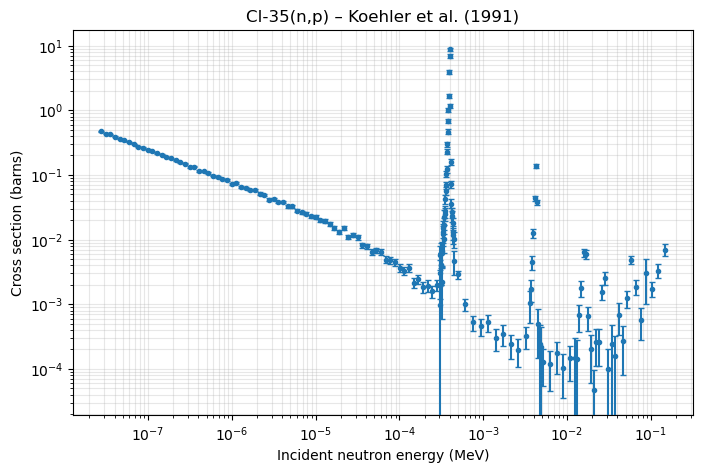

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.errorbar(
    koehler_df["energy_MeV"],
    koehler_df["cross_section_b"],
    yerr=koehler_df["uncertainty_b"],
    fmt="o",
    markersize=3,
    capsize=2
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Incident neutron energy (MeV)")
plt.ylabel("Cross section (barns)")
plt.title("Cl-35(n,p) – Koehler et al. (1991)")

plt.grid(True, which="both", alpha=0.3)
plt.show()